# Fuego en Manantay · ¿cuánto se quemó, qué se quemó, y es esta semana excepcional?

**Ciencia de Datos con Python · Diplomatura QLAB · Alexander Noblejas · 21 de octubre de 2026**

Manantay es uno de los cuatro distritos de Pucallpa, en Coronel Portillo, Ucayali.
Es periurbano: ciudad al norte, chacra y bosque secundario al sur. El fuego ahí no cae
sobre territorio vacío, y esa es la razón de elegirlo.

El trabajo responde cuatro preguntas, en este orden:

| # | Pregunta | Reto | Dato |
|---|---|---|---|
| 1 | ¿Es esta semana de octubre excepcional frente a 2012–2025? | **E** | FIRMS archivo |
| 2 | ¿Cuánto se quemó en Manantay? | **A** | dNBR Sentinel-2 |
| 3 | ¿Qué se quemó? | **C** | ESA WorldCover |
| 4 | ¿A quién llegó? | **D** | WorldPop + Open Buildings |

La cuarta es donde nos separamos del monitor de clase. WorldPop da personas por celda
de 1 km; **Google Open Buildings** da un polígono por techo. A la escala de un incendio
periurbano, esa diferencia es la que hay entre «unos miles de personas en la zona» y
«estas N construcciones quedaron a menos de un kilómetro del fuego».

> **Asumido desde el principio:** la computadora siempre da un número. Cada decisión
> —fechas, nubes, umbral, radios— está explícita acá y reportada en el README. Ninguna
> cifra del README o del tablero se escribe a mano: todas salen de `hallazgos.json`,
> que esta corrida genera.

## 0 · Preparación

```bash
pip install -r requirements.txt
```

La clave de FIRMS se lee de `.env` (que git ignora), nunca del código.
Todo corre en CPU.

In [1]:
import sys, warnings, json
from pathlib import Path

sys.path.append(str(Path.cwd().parent / "src"))

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import datos   # src/datos.py — todas las fuentes

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
plt.rcParams.update({"figure.dpi": 110, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25})

# ---- decisiones de método, todas en un solo lugar ----
RESOLUCION        = 20      # m por píxel: grilla común de todo el análisis raster
UMBRAL_QUEMADO    = 0.27    # dNBR, desde "moderada-baja" (Key & Benson)
RADIO_VIVIENDAS_M = 1000    # anillo para contar edificaciones expuestas
RADIO_POBLACION_M = 5000    # anillo para WorldPop, como pide la tarea
MARGEN_AOI_M      = 2000    # margen alrededor de la huella del incendio
VENTANA_DIAS      = 10      # tope del servicio FIRMS por consulta

Path("../outputs").mkdir(exist_ok=True)
Path("../figuras").mkdir(exist_ok=True)
print("listo")

listo


## 1 · Dónde arde el país esta semana

FIRMS publica cada día un CSV con todos los focos de calor de Sudamérica de los últimos
7 días; es descarga directa, sin clave.

Un **foco de calor no es un incendio**: es un píxel donde el satélite midió una anomalía
térmica. Puede ser un fuego forestal, una quema agrícola controlada, un horno ladrillero
o una antorcha de gas. Esa ambigüedad no se resuelve con código; se declara.

Descartamos los focos de confianza baja. Es una decisión, no un trámite: los `low`
incluyen reflejos y fuentes industriales fijas.

In [2]:
focos = datos.focos_7d("viirs-snpp", confianza_minima="n")

print(f"{len(focos):,} focos VIIRS de confianza nominal o alta en el Perú")
print(f"ventana: {focos.momento.min():%d-%b %H:%M} → "
      f"{focos.momento.max():%d-%b-%Y %H:%M} UTC")
focos[["latitude", "longitude", "momento", "confidence", "frp"]].head()

4,380 focos VIIRS de confianza nominal o alta en el Perú
ventana: 14-Oct 05:12 → 21-Oct-2026 18:58 UTC


,latitude,longitude,momento,confidence,frp
0,-0.07,-77.66,2026-10-14 06:50:00+00:00,nominal,1.29
1,-0.08,-77.66,2026-10-14 06:50:00+00:00,nominal,1.29
2,-0.08,-77.66,2026-10-14 06:50:00+00:00,nominal,1.34
3,-0.37,-76.88,2026-10-14 06:50:00+00:00,nominal,1.50
4,-0.53,-76.13,2026-10-14 06:50:00+00:00,nominal,1.30


3,171 de 4,380 focos cayeron dentro de un distrito (28% quedó en mar o al otro lado de la frontera)


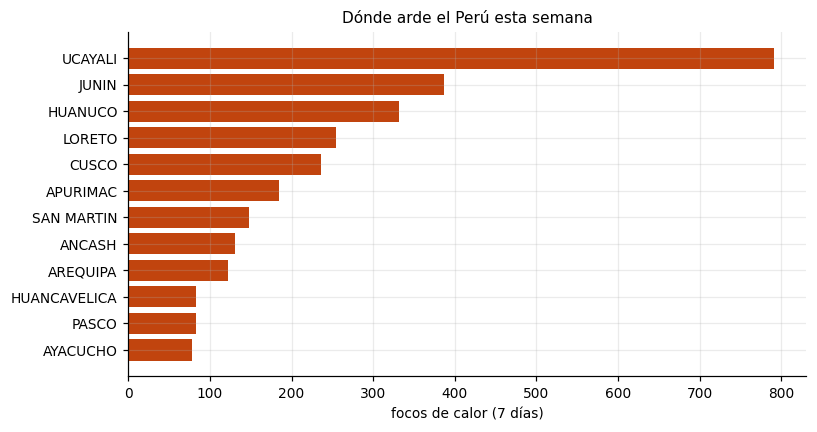

              focos       frp
departamento                 
UCAYALI         791 11,514.65
JUNIN           387  3,610.38
HUANUCO         331  4,018.58
LORETO          254  1,879.96
CUSCO           236  3,908.79
APURIMAC        184  3,834.30
SAN MARTIN      148    969.06
ANCASH          131  1,507.98


In [3]:
dist = datos.distritos()
assert dist.crs == focos.crs, "CRS distintos: reproyectar antes de cruzar"

cruce = gpd.sjoin(focos, dist[["departamento", "provincia", "distrito", "geometry"]],
                  how="inner", predicate="within")
print(f"{len(cruce):,} de {len(focos):,} focos cayeron dentro de un distrito "
      f"({1 - len(cruce)/len(focos):.0%} quedó en mar o al otro lado de la frontera)")

por_depa = (cruce.groupby("departamento")
                 .agg(focos=("frp", "size"), frp=("frp", "sum"))
                 .sort_values("focos", ascending=False))

fig, ax = plt.subplots(figsize=(7.5, 4))
t = por_depa.head(12)
ax.barh(t.index[::-1], t.focos[::-1], color="#c1440e")
ax.set_xlabel("focos de calor (7 días)")
ax.set_title("Dónde arde el Perú esta semana", fontsize=10)
plt.tight_layout(); plt.savefig("../figuras/01_focos_departamento.png",
                                bbox_inches="tight"); plt.show()

print(por_depa.head(8).to_string())

In [4]:
ranking_dist = (cruce.groupby(["departamento", "provincia", "distrito"])
                     .agg(focos=("frp", "size"), frp_total=("frp", "sum"))
                     .sort_values("frp_total", ascending=False)
                     .reset_index())

print("TOP 15 distritos por energía liberada (FRP acumulado, en MW)")
print(ranking_dist.head(15).to_string(index=False))

pos = ranking_dist.index[ranking_dist.distrito == "MANANTAY"]
print(f"\nManantay: puesto {int(pos[0]) + 1} de {len(ranking_dist)} distritos con fuego"
      if len(pos) else "\nManantay sin focos en esta ventana")

TOP 15 distritos por energía liberada (FRP acumulado, en MW)
departamento        provincia        distrito  focos  frp_total
     UCAYALI          ATALAYA        TAHUANIA    104   3,839.68
    APURIMAC          ABANCAY       CURAHUASI    110   2,306.36
     UCAYALI CORONEL PORTILLO         MASISEA    128   1,905.32
     UCAYALI CORONEL PORTILLO   NUEVA REQUENA    178   1,502.19
       JUNIN           SATIPO       RIO TAMBO    119   1,006.59
     UCAYALI CORONEL PORTILLO        MANANTAY     86     921.86
       CUSCO             ANTA       LIMATAMBO     31     804.71
       CUSCO           PARURO      HUANOQUITE     33     765.17
     UCAYALI          ATALAYA        RAYMONDI     62     735.35
     UCAYALI CORONEL PORTILLO     YARINACOCHA     56     730.63
       PASCO         OXAPAMPA PUERTO BERMUDEZ     53     649.36
     HUANUCO             AMBO           CAYNA     34     643.67
        PUNO         CHUCUITO            JULI      7     628.88
     HUANUCO      PUERTO INCA     PUERTO IN

## 2 · ¿Es excepcional? La misma ventana, catorce años atrás

El monitor de clase responde *dónde está el fuego ahora*. Acá agregamos *qué tan raro es*.

Para que la comparación valga, la ventana calendario tiene que ser **idéntica**: los
mismos diez días de octubre en cada año. Comparar un 2026 incompleto contra años
completos infla cualquier resultado, así que no lo hacemos.

Un aviso que hay que dar en voz alta: **2012–2025 sale del archivo reprocesado de
FIRMS (`VIIRS_SNPP_SP`) y 2026 del flujo casi en tiempo real (`VIIRS_SNPP_NRT`)**. Es el
mismo satélite —Suomi-NPP— con distinto procesamiento. No son intercambiables en
silencio; el código marca cada foco con su procedencia y acá lo decimos.

In [5]:
fin_ventana = focos.momento.max().date()
desde_ventana = fin_ventana - pd.Timedelta(days=VENTANA_DIAS - 1)
MES, DIA = desde_ventana.month, desde_ventana.day

print(f"ventana comparada: {DIA:02d}-{MES:02d} a "
      f"{(desde_ventana + pd.Timedelta(days=VENTANA_DIAS-1)):%d-%m}, "
      f"en cada año de 2012 a 2026\n")

serie = datos.serie_historica(MES, DIA, VENTANA_DIAS, anios=range(2012, 2027))
print(f"\n{len(serie):,} focos en total")
print(serie.groupby("procesamiento").size().to_string())

ventana comparada: 12-10 a 21-10, en cada año de 2012 a 2026




40,534 focos en total
procesamiento
NRT     3907
SP     36627


In [6]:
por_anio = serie.groupby("anio").size().rename("focos")
anios_ok = sorted(por_anio.index)
faltan = [a for a in range(2012, 2027) if a not in anios_ok]
if faltan:
    print(f"⚠ ADVERTENCIA · años sin cobertura comparable: {faltan}")
    print("  No se rellenan. Las conclusiones excluyen esos años.\n")

hist = por_anio[por_anio.index < 2026]
actual = int(por_anio.get(2026, 0))
promedio = hist.mean()
variacion = (actual / promedio - 1) * 100
puesto = int((por_anio.sort_values(ascending=False).index == 2026).argmax()) + 1

print(f"2026           : {actual:,} focos")
print(f"promedio 12-25 : {promedio:,.0f}")
print(f"variación      : {variacion:+.0f} %")
print(f"puesto de 2026 : {puesto} de {len(por_anio)} años")

2026           : 3,907 focos
promedio 12-25 : 2,616
variación      : +49 %
puesto de 2026 : 2 de 15 años


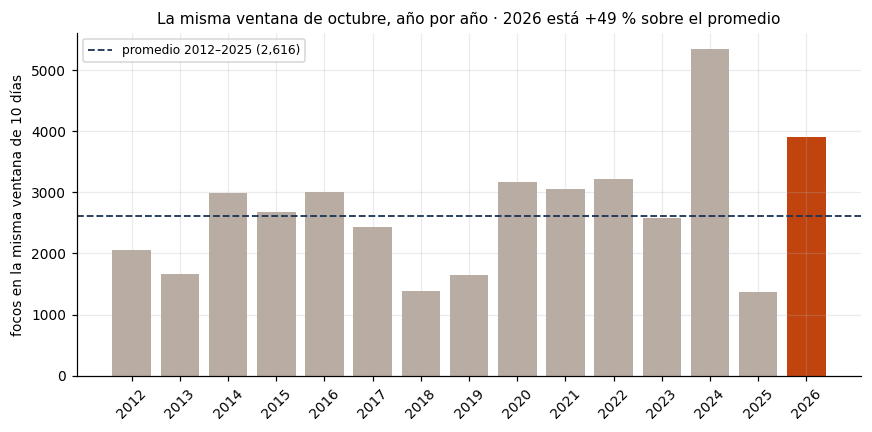

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
colores = ["#c1440e" if a == 2026 else "#b9aca2" for a in por_anio.index]
ax.bar(por_anio.index.astype(str), por_anio.values, color=colores)
ax.axhline(promedio, color="#1d3557", linestyle="--", linewidth=1.2,
           label=f"promedio 2012–2025 ({promedio:,.0f})")
ax.set_ylabel("focos en la misma ventana de 10 días")
ax.set_title(f"La misma ventana de octubre, año por año · "
             f"2026 está {variacion:+.0f} % sobre el promedio", fontsize=10)
ax.legend(fontsize=8)
plt.xticks(rotation=45); plt.tight_layout()
plt.savefig("../figuras/02_serie_historica.png", bbox_inches="tight"); plt.show()

In [8]:
anom = datos.anomalia_departamental(serie, anio_foco=2026)

print("Departamentos que explican la anomalía nacional")
print(anom.head(10)[["departamento", "focos_2026", "promedio", "diferencia",
                     "variacion_pct", "z", "puesto_en_su_serie",
                     "de_n_anios"]].to_string(index=False))

sobre = int((anom.focos_2026 > anom.promedio).sum())
print(f"\ndepartamentos por encima de su propio promedio: {sobre} de {len(anom)}")
lider = anom.iloc[0]
print(f"mayor anomalía absoluta: {lider.departamento} "
      f"({lider.diferencia:+,.0f} focos, z = {lider.z:+.1f})")

Departamentos que explican la anomalía nacional
departamento  focos_2026  promedio  diferencia  variacion_pct    z  puesto_en_su_serie  de_n_anios
     UCAYALI      935.00    524.43      410.57          78.29 1.34                   2          15
       JUNIN      460.00    215.00      245.00         113.95 3.01                   1          15
      ANCASH      187.00     27.07      159.93         590.77 6.86                   1          15
    APURIMAC      217.00     60.07      156.93         261.24 1.23                   2          15
       CUSCO      291.00    150.36      140.64          93.54 1.50                   2          15
     HUANUCO      402.00    284.43      117.57          41.34 0.91                   4          15
    AREQUIPA      131.00     31.93       99.07         310.29 4.73                   1          15
HUANCAVELICA      112.00     40.07       71.93         179.50 1.76                   2          15
    MOQUEGUA       81.00     21.07       59.93         284.41

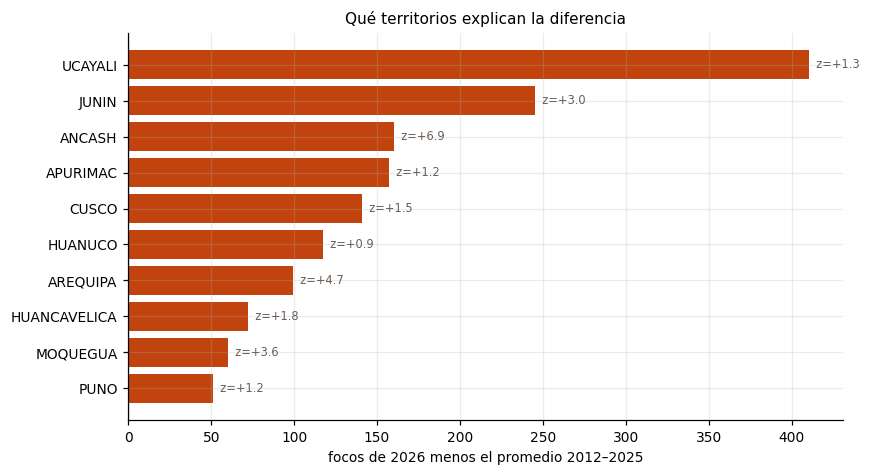

In [9]:
fig, ax = plt.subplots(figsize=(8, 4.4))
t = anom.head(10).iloc[::-1]
ax.barh(t.departamento, t.diferencia, color="#c1440e")
ax.axvline(0, color="#555", linewidth=0.8)
ax.set_xlabel("focos de 2026 menos el promedio 2012–2025")
ax.set_title("Qué territorios explican la diferencia", fontsize=10)
for i, (d, z) in enumerate(zip(t.diferencia, t.z)):
    if np.isfinite(z):
        ax.text(d, i, f"  z={z:+.1f}", va="center", fontsize=7.5,
                color="#6b5d53")
plt.tight_layout(); plt.savefig("../figuras/03_anomalia_departamental.png",
                                bbox_inches="tight"); plt.show()

## 3 · Del foco al incendio

Un incendio grande produce decenas de focos repartidos en el tiempo. Para contar
*incendios* y no *detecciones*, hay que agruparlos. Usamos la regla del monitor de clase:
**dos focos son el mismo incendio si están a menos de 1 km y a menos de 48 horas.**

Implementado como DBSCAN sobre tres ejes —x, y, y el tiempo convertido a metros— de modo
que una sola distancia gobierna espacio y tiempo a la vez.

La columna `huella_ha` es el buffer de 375 m (el tamaño del píxel VIIRS) alrededor de
cada foco, unido. **La huella VIIRS no son hectáreas quemadas**: es un proxy operativo
construido desde detecciones térmicas. Sobreestima los fuegos puntuales y subestima los
grandes. La medición del área quemada sale del raster, más adelante.

In [10]:
zona = datos.distrito("MANANTAY", "UCAYALI")
print(f"Manantay · {zona.iloc[0]['provincia']}, {zona.iloc[0]['departamento']} · "
      f"UBIGEO {zona.iloc[0]['ubigeo']}")
print(f"superficie: {datos.a_metros(zona).area.iloc[0] / 1e6:,.0f} km²")

focos_zona = gpd.sjoin(focos, zona[["geometry"]], predicate="within").drop(
    columns="index_right")
agrupados = datos.agrupar_incendios(focos_zona, radio_km=1.0, horas=48.0)
incendios = datos.resumen_incendios(agrupados, buffer_m=375)

print(f"\n{len(focos_zona)} focos → {len(incendios)} incendios distintos\n")
print(incendios[["incendio_id", "n_focos", "frp_total", "frp_max",
                 "inicio", "fin", "horas", "huella_ha"]].head(8).to_string(index=False))

Manantay · CORONEL PORTILLO, UCAYALI · UBIGEO 250107
superficie: 657 km²



86 focos → 15 incendios distintos

 incendio_id  n_focos  frp_total  frp_max                    inicio                       fin  horas  huella_ha
           1       51     643.93    41.29 2026-10-15 06:33:00+00:00 2026-10-16 18:49:00+00:00  36.27   1,133.42
          12        3      69.32    23.42 2026-10-16 18:49:00+00:00 2026-10-16 18:49:00+00:00   0.00     100.96
           3        5      41.82    11.20 2026-10-15 19:10:00+00:00 2026-10-16 18:49:00+00:00  23.65     108.60
           5        2      40.62    20.31 2026-10-15 19:10:00+00:00 2026-10-15 19:10:00+00:00   0.00      80.41
          10        6      29.25     6.57 2026-10-16 18:49:00+00:00 2026-10-16 18:49:00+00:00   0.00     195.60
           4        3      25.01    11.26 2026-10-15 19:10:00+00:00 2026-10-16 18:49:00+00:00  23.65      93.60
           2        6      24.37     8.07 2026-10-15 19:10:00+00:00 2026-10-16 18:49:00+00:00  23.65     162.39
           6        2      12.99     7.01 2026-10-15 19:10:00+00:00 

### Atención prioritaria

Un ranking reproducible, con la fórmula a la vista. No se oculta porque es discutible:

$$\text{prioridad} = \log(1+\text{FRP total}) \;\times\; \log(1+\text{huella ha}) \;\times\; (1 + \text{focos últimas 24 h})$$

Los logaritmos van porque el FRP y la huella son brutalmente asimétricos: sin ellos el
incendio más grande aplasta a todos los demás. El factor de las últimas 24 horas premia
lo que **sigue activo**, que es lo que importa para atender.

In [11]:
corte_24h = focos.momento.max() - pd.Timedelta(hours=24)
recientes = (agrupados[agrupados.momento >= corte_24h]
             .groupby("incendio_id").size().rename("focos_24h"))

incendios["focos_24h"] = incendios["incendio_id"].map(recientes).fillna(0).astype(int)
incendios["prioridad"] = (np.log1p(incendios.frp_total)
                          * np.log1p(incendios.huella_ha)
                          * (1 + incendios.focos_24h))

print("Atención prioritaria en Manantay")
print(incendios.nlargest(6, "prioridad")[
    ["incendio_id", "n_focos", "focos_24h", "frp_total", "huella_ha",
     "horas", "prioridad"]].to_string(index=False))

Atención prioritaria en Manantay
 incendio_id  n_focos  focos_24h  frp_total  huella_ha  horas  prioridad
           1       51          0     643.93   1,133.42  36.27      45.50
          12        3          0      69.32     100.96   0.00      19.67
          10        6          0      29.25     195.60   0.00      18.01
           3        5          0      41.82     108.60  23.65      17.65
           2        6          0      24.37     162.39  23.65      16.48
           5        2          0      40.62      80.41   0.00      16.40


## 4 · El incendio elegido y su área de interés

Tomamos el de mayor energía liberada y definimos el AOI con un margen de 2 km. Las
fechas de las imágenes salen del propio incendio: la de **antes** debe ser anterior al
primer foco; la de **después**, posterior al último.

In [12]:
EVENTO = incendios.sort_values("frp_total", ascending=False).iloc[0]

print(f"incendio #{EVENTO.incendio_id}")
print(f"  focos        : {EVENTO.n_focos}  ({EVENTO.focos_24h} en las últimas 24 h)")
print(f"  FRP total    : {EVENTO.frp_total:,.0f} MW   (máx {EVENTO.frp_max:,.1f} MW)")
print(f"  activo       : {EVENTO.inicio:%d-%b %H:%M} → {EVENTO.fin:%d-%b %H:%M} UTC "
      f"({EVENTO.horas:.0f} h)")
print(f"  huella proxy : {EVENTO.huella_ha:,.0f} ha  (NO es área quemada)")

aoi_m = gpd.GeoDataFrame(geometry=[EVENTO.geometry.buffer(MARGEN_AOI_M)],
                         crs=datos.CRS_METRICO)
BBOX = tuple(aoi_m.to_crs(4326).total_bounds)
INICIO_FUEGO, FIN_FUEGO = EVENTO.inicio.date(), EVENTO.fin.date()

print(f"\nAOI: {aoi_m.area.iloc[0] / 1e4:,.0f} ha")
print(f"bbox: {[round(v, 4) for v in BBOX]}")

incendio #1
  focos        : 51  (0 en las últimas 24 h)
  FRP total    : 644 MW   (máx 41.3 MW)
  activo       : 15-Oct 06:33 → 16-Oct 18:49 UTC (36 h)
  huella proxy : 1,133 ha  (NO es área quemada)

AOI: 6,710 ha
bbox: [-74.5776, -8.5302, -74.4961, -8.4316]


## 5 · Las imágenes: fechas y nubes antes de calcular nada

Este es el paso que decide si el número final es creíble. Sentinel-2 pasa cada 5 días,
pero en la selva de Ucayali en octubre **la nube manda**.

Y hay una trampa: `eo:cloud_cover` es la nubosidad de la escena completa, 110 × 110 km.
Lo que importa es la nubosidad **sobre nuestro AOI**, que es algo muy distinto y se
calcula con la capa SCL. Por eso listamos las candidatas con ambas cifras y **no**
elegimos por `eo:cloud_cover`.

In [13]:
candidatas_antes = datos.buscar_sentinel2(
    BBOX, str(INICIO_FUEGO - pd.Timedelta(days=60)), str(INICIO_FUEGO), nubes_max=100)
candidatas_despues = datos.buscar_sentinel2(
    BBOX, str(FIN_FUEGO), str(FIN_FUEGO + pd.Timedelta(days=25)), nubes_max=100)

print(f"{len(candidatas_antes)} candidatas antes · "
      f"{len(candidatas_despues)} después\n")
print("ANTES (las últimas 8):")
print(datos.tabla_escenas(candidatas_antes).tail(8).to_string(index=False))
print("\nDESPUÉS (las primeras 8):")
print(datos.tabla_escenas(candidatas_despues).head(8).to_string(index=False))

17 candidatas antes · 2 después

ANTES (las últimas 8):
                                                    id      fecha  nubes_escena_pct  mgrs
S2C_MSIL2A_20260921T151721_R125_T18LWR_20260921T200217 2026-09-21              1.10 18LWR
S2A_MSIL2A_20260923T151931_R125_T18LWR_20260923T231509 2026-09-23             59.82 18LWR
S2B_MSIL2A_20260926T151719_R125_T18LWR_20260926T203223 2026-09-26             96.44 18LWR
S2C_MSIL2A_20261001T151721_R125_T18LWR_20261001T200007 2026-10-01             99.99 18LWR
S2A_MSIL2A_20261003T151731_R125_T18LWR_20261003T232200 2026-10-03             39.57 18LWR
S2B_MSIL2A_20261006T151719_R125_T18LWR_20261006T202909 2026-10-06             28.09 18LWR
S2C_MSIL2A_20261011T151721_R125_T18LWR_20261011T194304 2026-10-11             39.04 18LWR
S2A_MSIL2A_20261013T151931_R125_T18LWR_20261013T224308 2026-10-13             69.57 18LWR

DESPUÉS (las primeras 8):
                                                    id      fecha  nubes_escena_pct  mgrs
S2B_MSIL2A_202610

In [14]:
def elegir(items, etiqueta, maximo=8):
    "Elige por nubes sobre el AOI (SCL), no por la nubosidad de la escena."
    orden = items[::-1] if etiqueta == "antes" else items
    mejor = None
    filas = []
    for it in orden[:maximo]:
        try:
            ds = datos.leer_bandas(it, BBOX, RESOLUCION)
        except Exception as e:
            print(f"  {it.datetime.date()}  no se pudo leer ({type(e).__name__})")
            continue
        pct = datos.pct_nubes(ds)
        filas.append({"fecha": it.datetime.date(),
                      "nubes_escena_pct": it.properties.get("eo:cloud_cover"),
                      "invalidos_aoi_pct": round(pct, 1)})
        print(f"  {it.datetime.date()}  escena "
              f"{it.properties.get('eo:cloud_cover'):5.1f}%  →  AOI {pct:5.1f}%")
        if mejor is None or pct < mejor[1]:
            mejor = (it, pct, ds)
    if mejor is None:
        raise RuntimeError(f"Ninguna escena {etiqueta} se pudo leer")
    print(f"  → elegida: {mejor[0].datetime.date()} ({mejor[1]:.1f}% inválidos)\n")
    return (*mejor, pd.DataFrame(filas))

print("ANTES:")
it_antes, nubes_antes, ds_antes, tabla_antes = elegir(candidatas_antes, "antes")
print("DESPUÉS:")
it_despues, nubes_despues, ds_despues, tabla_despues = elegir(candidatas_despues, "después")

FECHA_ANTES, FECHA_DESPUES = it_antes.datetime.date(), it_despues.datetime.date()
print(f"par elegido: {FECHA_ANTES} → {FECHA_DESPUES} "
      f"({(FECHA_DESPUES - FECHA_ANTES).days} días de separación)")

# Sentinel-2 pasa sobre el Perú a media mañana. Si la imagen posterior es del
# mismo día en que el incendio seguía detectándose, la toma captura el fuego
# EN CURSO: parte del área puede no haber ardido todavía. Es la misma salvedad
# que el profesor puso en su tabla de Curahuasi ("fuego activo"), y se declara.
FUEGO_ACTIVO = FECHA_DESPUES <= FIN_FUEGO
if FUEGO_ACTIVO:
    print(f"\n⚠ la imagen posterior ({FECHA_DESPUES}) es del mismo día en que el "
          f"incendio seguía activo ({EVENTO.fin:%d-%b %H:%M} UTC).")
    print("  El área quemada medida es por tanto un PISO adicional: lo que ardió")
    print("  después de la toma no aparece. Se reporta así, no se corrige.")

ANTES:


  2026-10-13  escena  69.6%  →  AOI 100.0%


  2026-10-11  escena  39.0%  →  AOI  26.2%


  2026-10-06  escena  28.1%  →  AOI  17.8%


  2026-10-03  escena  39.6%  →  AOI  25.9%


...

  2026-09-26  escena  96.4%  →  AOI 100.0%


  2026-09-23  escena  59.8%  →  AOI  68.3%


  2026-09-21  escena   1.1%  →  AOI   1.2%
  → elegida: 2026-09-21 (1.2% inválidos)

DESPUÉS:


  2026-10-16  escena   7.9%  →  AOI   9.9%


  2026-10-21  escena  94.7%  →  AOI  66.5%
  → elegida: 2026-10-16 (9.9% inválidos)

par elegido: 2026-09-21 → 2026-10-16 (25 días de separación)

⚠ la imagen posterior (2026-10-16) es del mismo día en que el incendio seguía activo (16-Oct 18:49 UTC).
  El área quemada medida es por tanto un PISO adicional: lo que ardió
  después de la toma no aparece. Se reporta así, no se corrige.


### Inspeccionar antes de operar

Lo que el curso insiste en mirar siempre: CRS, tamaño, bandas, nodata, dtype, extensión,
resolución, píxeles válidos, mínimo y máximo. Saltarse este paso es donde se esconden los
errores que después no se explican.

In [15]:
datos.inspeccionar(ds_antes, f"Sentinel-2 ANTES · {FECHA_ANTES}")
print()
datos.inspeccionar(ds_despues, f"Sentinel-2 DESPUÉS · {FECHA_DESPUES}")

=== Sentinel-2 ANTES · 2026-09-21 ===
CRS          : PROJCRS["WGS 84 / UTM zone 18S",BASEGEOGCRS["WGS 84",ENSEMBLE["World Geodetic System 1984 ensemble",MEMBER["World Geodetic System 1984 (Transit)"],MEMBER["World Geodetic System 1984 (G730)"],MEMBER["World Geodetic System 1984 (G873)"],MEMBER["World Geodetic System 1984 (G1150)"],MEMBER["World Geodetic System 1984 (G1674)"],MEMBER["World Geodetic System 1984 (G1762)"],MEMBER["World Geodetic System 1984 (G2139)"],MEMBER["World Geodetic System 1984 (G2296)"],ELLIPSOID["WGS 84",6378137,298.257223563,LENGTHUNIT["metre",1]],ENSEMBLEACCURACY[2.0]],PRIMEM["Greenwich",0,ANGLEUNIT["degree",0.0174532925199433]],ID["EPSG",4326]],CONVERSION["UTM zone 18S",METHOD["Transverse Mercator",ID["EPSG",9807]],PARAMETER["Latitude of natural origin",0,ANGLEUNIT["degree",0.0174532925199433],ID["EPSG",8801]],PARAMETER["Longitude of natural origin",-75,ANGLEUNIT["degree",0.0174532925199433],ID["EPSG",8802]],PARAMETER["Scale factor at natural origin",0.9996,SCA

In [16]:
# Dos raster solo se operan juntos si comparten grilla exactamente.
assert datos.misma_grilla(ds_antes, ds_despues), \
    "las dos escenas no están en la misma grilla: no se pueden restar"
print("ambas escenas en la misma grilla "
      f"({ds_antes['B08'].shape[0]} × {ds_antes['B08'].shape[1]} px, "
      f"{RESOLUCION} m, EPSG:{datos.CRS_METRICO.split(':')[1]}) — se pueden restar")

ambas escenas en la misma grilla (547 × 450 px, 20 m, EPSG:32718) — se pueden restar


## 6 · NBR y dNBR

El **Normalized Burn Ratio** contrasta el infrarrojo cercano (B08), que la vegetación
sana refleja mucho, con el infrarrojo de onda corta (B12), que el suelo quemado y seco
refleja mucho:

$$\text{NBR} = \frac{\text{B08} - \text{B12}}{\text{B08} + \text{B12}}
\qquad
\text{dNBR} = \text{NBR}_{\text{antes}} - \text{NBR}_{\text{después}}$$

Quedan fuera, vía SCL: sin dato, saturados, sombra de nube, nube de probabilidad media
y alta, cirros y nieve/hielo. La máscara se propaga sola al restar, porque `NaN − x = NaN`:
un píxel tapado en *cualquiera* de las dos fechas no entra.

In [17]:
nbr_antes = datos.nbr(ds_antes)
nbr_despues = datos.nbr(ds_despues)
dnbr = nbr_antes - nbr_despues

validos = np.isfinite(dnbr.values)
pct_validos = float(validos.mean() * 100)

print(f"píxeles utilizables: {validos.sum():,} de {dnbr.size:,} "
      f"({pct_validos:.1f} %)")
print(f"el resto quedó bajo nube en alguna de las dos fechas\n")
print(f"dNBR  mediana {np.nanmedian(dnbr.values):+.3f} · "
      f"p95 {np.nanpercentile(dnbr.values, 95):+.3f} · "
      f"máx {np.nanmax(dnbr.values):+.3f}")

píxeles utilizables: 218,959 de 246,150 (89.0 %)
el resto quedó bajo nube en alguna de las dos fechas

dNBR  mediana +0.043 · p95 +0.411 · máx +1.104


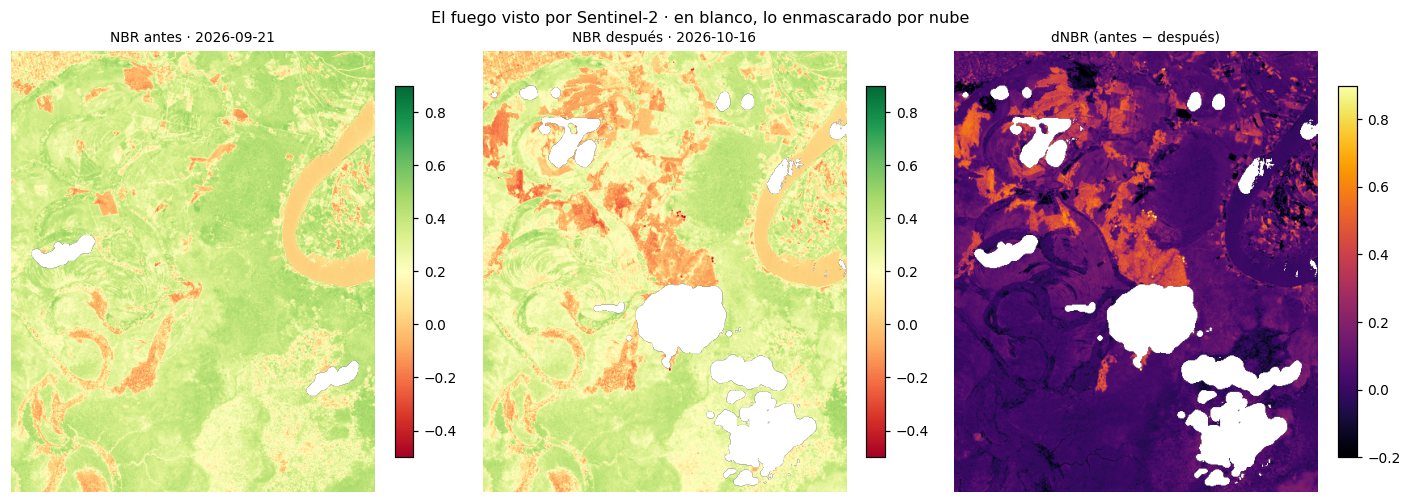

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.6))
for ax, capa, titulo, cmap, lim in [
    (axes[0], nbr_antes,   f"NBR antes · {FECHA_ANTES}",     "RdYlGn", (-0.5, 0.9)),
    (axes[1], nbr_despues, f"NBR después · {FECHA_DESPUES}", "RdYlGn", (-0.5, 0.9)),
    (axes[2], dnbr,        "dNBR (antes − después)",         "inferno", (-0.2, 0.9)),
]:
    im = ax.imshow(capa.values, cmap=cmap, vmin=lim[0], vmax=lim[1])
    ax.set_title(titulo, fontsize=9); ax.axis("off")
    fig.colorbar(im, ax=ax, fraction=0.045)
fig.suptitle("El fuego visto por Sentinel-2 · en blanco, lo enmascarado por nube",
             fontsize=10.5)
plt.tight_layout(); plt.savefig("../figuras/04_nbr_dnbr.png",
                                bbox_inches="tight"); plt.show()

## 7 · Severidad y hectáreas · el número depende del umbral

Los umbrales son los de Key & Benson (USGS), estándar en la literatura, y están
configurables arriba. **No son universalmente válidos**: la clasificación depende del
ecosistema, del sensor, de las fechas y de la validación de campo disponible, que acá no
tenemos.

La frontera entre «quemado» y «no quemado» es nuestra decisión: tomamos dNBR ≥ 0.27.
Con 0.10 el número se infla con ruido de sequía; con 0.44 se pierde el borde real del
fuego. Mostramos los cuatro, que es la tabla que el profesor mostró para Curahuasi.

In [19]:
sev = datos.hectareas_por_severidad(dnbr, RESOLUCION)
print(sev.to_string(index=False))

ha_quemadas = float(sev.loc[sev.dnbr_min >= UMBRAL_QUEMADO, "hectareas"].sum())
print(f"\nÁREA QUEMADA (dNBR ≥ {UMBRAL_QUEMADO}): {ha_quemadas:,.0f} ha")
print(f"huella proxy VIIRS, para contraste: {EVENTO.huella_ha:,.0f} ha")

                  clase  dnbr_min  dnbr_max  hectareas
                Rebrote      -inf     -0.10     211.68
             Sin cambio     -0.10      0.10   6,152.52
         Severidad baja      0.10      0.27   1,502.68
Severidad moderada-baja      0.27      0.44     584.16
Severidad moderada-alta      0.44      0.66     304.68
         Severidad alta      0.66       inf       2.64

ÁREA QUEMADA (dNBR ≥ 0.27): 891 ha
huella proxy VIIRS, para contraste: 1,133 ha


In [20]:
sens = pd.DataFrame([
    {"umbral dNBR": u,
     "hectáreas": float((dnbr.values >= u).sum()) * (RESOLUCION ** 2) / 1e4}
    for u in [0.10, UMBRAL_QUEMADO, 0.44, 0.66]])
print("La misma imagen, cuatro umbrales:\n")
print(sens.to_string(index=False))
print(f"\nReportamos {UMBRAL_QUEMADO}. Los otros tres son el intervalo de lo defendible.")

La misma imagen, cuatro umbrales:

 umbral dNBR  hectáreas
        0.10   2,394.16
        0.27     891.48
        0.44     307.32
        0.66       2.64

Reportamos 0.27. Los otros tres son el intervalo de lo defendible.


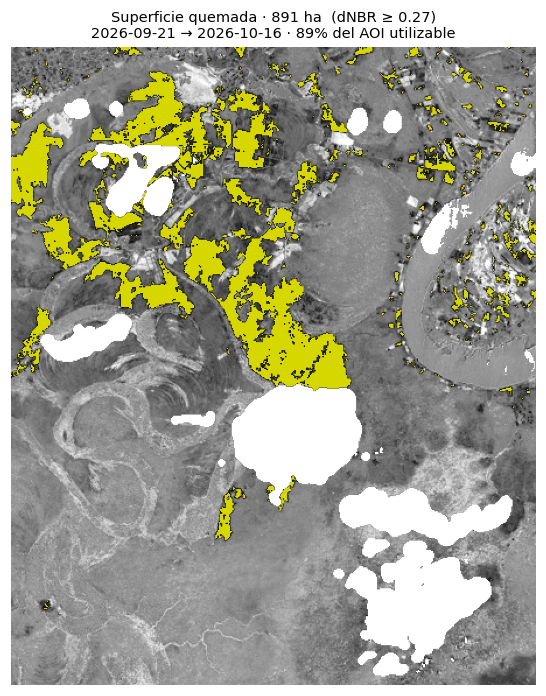

In [21]:
quemado = dnbr >= UMBRAL_QUEMADO

fig, ax = plt.subplots(figsize=(7, 6.4))
ax.imshow(np.where(np.isfinite(dnbr.values), dnbr.values, np.nan),
          cmap="Greys", vmin=-0.3, vmax=0.3)
ax.imshow(np.where(quemado.values, 1, np.nan), cmap="autumn_r", alpha=0.85)
ax.set_title(f"Superficie quemada · {ha_quemadas:,.0f} ha  (dNBR ≥ {UMBRAL_QUEMADO})\n"
             f"{FECHA_ANTES} → {FECHA_DESPUES} · "
             f"{pct_validos:.0f}% del AOI utilizable", fontsize=9.5)
ax.axis("off")
plt.tight_layout(); plt.savefig("../figuras/05_area_quemada.png",
                                bbox_inches="tight"); plt.show()

## 8 · ¿Qué se quemó?

ESA WorldCover clasifica el planeta a 10 m en once clases. Lo cargamos con `like=ds_antes`,
que lo pone en **exactamente la misma grilla** que el dNBR —mismo CRS, mismo transform,
mismo ancho y alto— y con remuestreo **nearest-neighbor**, porque es categórico:
promediar códigos de clase no significa nada.

Después contamos hectáreas solo sobre los píxeles clasificados como quemados.

In [22]:
cobertura = datos.worldcover(like=ds_antes)
datos.inspeccionar(cobertura.to_dataset(name="map"), "ESA WorldCover 2021")

assert datos.misma_grilla(cobertura, dnbr), \
    "WorldCover no quedó en la grilla del dNBR: el cruce daría basura"
print("\nWorldCover en la misma grilla que el dNBR — se puede cruzar")

=== ESA WorldCover 2021 ===
CRS          : PROJCRS["WGS 84 / UTM zone 18S",BASEGEOGCRS["WGS 84",ENSEMBLE["World Geodetic System 1984 ensemble",MEMBER["World Geodetic System 1984 (Transit)"],MEMBER["World Geodetic System 1984 (G730)"],MEMBER["World Geodetic System 1984 (G873)"],MEMBER["World Geodetic System 1984 (G1150)"],MEMBER["World Geodetic System 1984 (G1674)"],MEMBER["World Geodetic System 1984 (G1762)"],MEMBER["World Geodetic System 1984 (G2139)"],MEMBER["World Geodetic System 1984 (G2296)"],ELLIPSOID["WGS 84",6378137,298.257223563,LENGTHUNIT["metre",1]],ENSEMBLEACCURACY[2.0]],PRIMEM["Greenwich",0,ANGLEUNIT["degree",0.0174532925199433]],ID["EPSG",4326]],CONVERSION["UTM zone 18S",METHOD["Transverse Mercator",ID["EPSG",9807]],PARAMETER["Latitude of natural origin",0,ANGLEUNIT["degree",0.0174532925199433],ID["EPSG",8801]],PARAMETER["Longitude of natural origin",-75,ANGLEUNIT["degree",0.0174532925199433],ID["EPSG",8802]],PARAMETER["Scale factor at natural origin",0.9996,SCALEUNIT["un

           clase  hectareas   pct
        Pastizal     655.56 73.54
          Bosque     214.72 24.09
Humedal herbáceo      19.88  2.23
        Matorral       0.88  0.10
            Agua       0.24  0.03
 Área construida       0.20  0.02


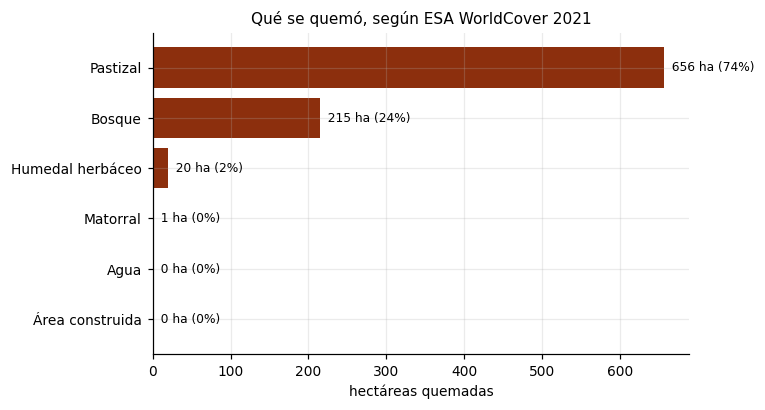

In [23]:
tabla_cob = datos.que_se_quemo(cobertura, quemado, RESOLUCION)
print(tabla_cob.to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 3.8))
t = tabla_cob.head(6)
ax.barh(t["clase"][::-1], t["hectareas"][::-1], color="#8c2f0d")
for i, (ha, pct) in enumerate(zip(t.hectareas[::-1], t.pct[::-1])):
    ax.text(ha, i, f"  {ha:,.0f} ha ({pct:.0f}%)", va="center", fontsize=8)
ax.set_xlabel("hectáreas quemadas")
ax.set_title("Qué se quemó, según ESA WorldCover 2021", fontsize=10)
plt.tight_layout(); plt.savefig("../figuras/06_que_se_quemo.png",
                                bbox_inches="tight"); plt.show()

WorldCover es de 2021 y el fuego es de 2026. En un distrito con frente agrícola activo,
ese desfase de cinco años va en una dirección conocida: **subestima** agricultura y
construcción, **sobreestima** bosque.

## 9 · ¿A quién llegó?

Dos medidas, a dos escalas. **WorldPop (1 km)** da personas por celda: sirve para el
orden de magnitud a 5 km. **Google Open Buildings** da un polígono por techo: sirve para
decir cuántas construcciones quedaron realmente al borde del fuego.

In [24]:
from rasterstats import zonal_stats

anillo_pob = gpd.GeoDataFrame(
    geometry=[EVENTO.geometry.buffer(RADIO_POBLACION_M)], crs=datos.CRS_METRICO)
pob = zonal_stats(anillo_pob.to_crs(4326), str(datos.worldpop()),
                  stats=["sum"], nodata=-99999, all_touched=True)[0]["sum"] or 0

print(f"población a {RADIO_POBLACION_M/1000:.0f} km del incendio "
      f"(WorldPop 2020, 1 km): {pob:,.0f} personas")

población a 5 km del incendio (WorldPop 2020, 1 km): 49,363 personas


In [25]:
# El tile de Open Buildings que cubre Pucallpa pesa ~490 MB. Se descarga una
# sola vez y queda en cache, pero si la red falla NO debe tumbar el análisis:
# el resto de los hallazgos no dependen de esta capa.
anillo_viv = EVENTO.geometry.buffer(RADIO_VIVIENDAS_M)
edificios = cerca = None

try:
    edificios = datos.open_buildings(aoi_m.to_crs(4326), confianza_min=0.70)
    ed_m = datos.a_metros(edificios)
    cerca = ed_m[ed_m.intersects(anillo_viv)]
    print(f"\n{len(edificios):,} edificaciones en el AOI")
    print(f"a menos de {RADIO_VIVIENDAS_M} m del fuego: {len(cerca):,}")
    print(f"superficie construida expuesta: "
          f"{cerca.area_in_meters.sum()/1e4:,.1f} ha")
    if len(cerca):
        print(f"tamaño mediano: {cerca.area_in_meters.median():,.0f} m²")
except Exception as e:
    print(f"\n⚠ Open Buildings no disponible en esta corrida "
          f"({type(e).__name__}: {e})")
    print("  El resto del análisis continúa; el hallazgo 3 se omite y se dice.")

  tile 91b (492 MB) — se descarga una sola vez y queda en cache



295 edificaciones en el AOI
a menos de 1000 m del fuego: 35
superficie construida expuesta: 0.2 ha
tamaño mediano: 42 m²


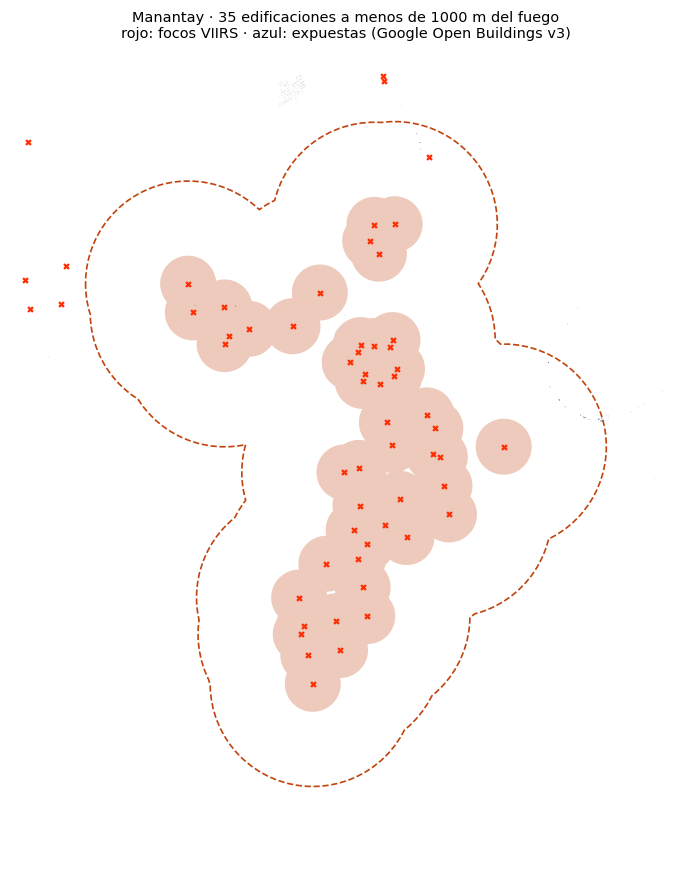

In [26]:
fig, ax = plt.subplots(figsize=(8, 8))
datos.a_metros(zona).boundary.plot(ax=ax, color="#999", linewidth=0.8)
gpd.GeoSeries([anillo_viv], crs=datos.CRS_METRICO).plot(
    ax=ax, facecolor="none", edgecolor="#c1440e", linestyle="--", linewidth=1.1)
gpd.GeoSeries([EVENTO.geometry], crs=datos.CRS_METRICO).plot(
    ax=ax, color="#c1440e", alpha=0.28)
if edificios is not None and len(edificios):
    datos.a_metros(edificios).plot(ax=ax, color="#c8ccd4", markersize=0.5,
                                   linewidth=0)
if cerca is not None and len(cerca):
    cerca.plot(ax=ax, color="#1d3557", markersize=1.5, linewidth=0)
datos.a_metros(agrupados).plot(ax=ax, color="#ff2d00", markersize=10, marker="x")

minx, miny, maxx, maxy = aoi_m.total_bounds
ax.set_xlim(minx, maxx); ax.set_ylim(miny, maxy)
ax.set_title((f"Manantay · {len(cerca):,} edificaciones a menos de "
              f"{RADIO_VIVIENDAS_M} m del fuego" if cerca is not None
              else f"Manantay · huella del fuego y anillo de "
                   f"{RADIO_VIVIENDAS_M} m") + "\n"
             "rojo: focos VIIRS · azul: expuestas (Google Open Buildings v3)",
             fontsize=9.5)
ax.set_axis_off()
plt.tight_layout(); plt.savefig("../figuras/07_edificaciones_expuestas.png",
                                bbox_inches="tight"); plt.show()

## 10 · El mapa

In [27]:
import folium

m = folium.Map(location=[EVENTO.lat, EVENTO.lon], zoom_start=12,
               tiles="CartoDB positron")
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/"
          "World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Esri", name="Satélite").add_to(m)

folium.GeoJson(zona.to_json(), name="Manantay",
               style_function=lambda f: {"color": "#444", "weight": 1.5,
                                         "fillOpacity": 0}).add_to(m)
folium.GeoJson(
    gpd.GeoDataFrame(geometry=[anillo_viv], crs=datos.CRS_METRICO)
       .to_crs(4326).to_json(), name=f"Anillo {RADIO_VIVIENDAS_M} m",
    style_function=lambda f: {"color": "#c1440e", "weight": 1.5,
                              "dashArray": "6", "fillOpacity": 0.05}).add_to(m)
# GeoJSON no sabe serializar Timestamps: las fechas van como texto.
huellas = incendios.to_crs(4326).copy()
for col in ("inicio", "fin"):
    huellas[col] = huellas[col].dt.strftime("%d-%b %H:%M UTC")

folium.GeoJson(
    huellas.to_json(), name="Huella VIIRS (proxy)",
    tooltip=folium.GeoJsonTooltip(
        fields=["incendio_id", "n_focos", "frp_total", "inicio", "fin"],
        aliases=["incendio", "focos", "FRP (MW)", "primer foco", "último foco"]),
    style_function=lambda f: {"color": "#7a1500", "weight": 1,
                              "fillOpacity": 0.25}).add_to(m)

for _, r in agrupados.iterrows():
    folium.CircleMarker(
        [r.latitude, r.longitude], radius=4, color="#ff2d00",
        fill=True, fill_opacity=0.85,
        popup=f"{r.momento:%d-%b %H:%M} UTC · FRP {r.frp:.1f} MW").add_to(m)

folium.LayerControl().add_to(m)
m.save("../outputs/mapa_manantay.html")
m

## 11 · Exportar

Todo a un JSON. El README y el tablero se generan a partir de él, así que **ninguna
cifra se escribe a mano en ningún lado**.

In [28]:
hallazgos = {
    "distrito": "Manantay", "provincia": str(zona.iloc[0]["provincia"]),
    "departamento": str(zona.iloc[0]["departamento"]),
    "ubigeo": str(zona.iloc[0]["ubigeo"]),
    "corte": pd.Timestamp.utcnow().strftime("%Y-%m-%d %H:%M UTC"),

    "nacional": {
        "focos_7d": int(len(focos)),
        "ventana": [str(focos.momento.min()), str(focos.momento.max())],
        "departamento_mas_focos": str(por_depa.index[0]),
        "focos_ese_departamento": int(por_depa.iloc[0]["focos"]),
        "puesto_manantay": int(pos[0]) + 1 if len(pos) else None,
        "distritos_con_fuego": int(len(ranking_dist)),
    },
    "historico": {
        "ventana_dias": VENTANA_DIAS,
        "ventana_calendario": f"{DIA:02d}-{MES:02d} + {VENTANA_DIAS} días",
        "anios_disponibles": [int(a) for a in anios_ok],
        "anios_faltantes": [int(a) for a in faltan],
        "focos_2026": actual,
        "promedio_2012_2025": round(float(promedio), 1),
        "variacion_pct": round(float(variacion), 1),
        "puesto_2026": puesto,
        "de_n_anios": int(len(por_anio)),
        "departamentos_sobre_su_promedio": sobre,
        "de_n_departamentos": int(len(anom)),
        "mayor_anomalia": {
            "departamento": str(lider.departamento),
            "focos_2026": int(lider.focos_2026),
            "promedio": round(float(lider.promedio), 1),
            "diferencia": round(float(lider.diferencia), 1),
            "z": None if not np.isfinite(lider.z) else round(float(lider.z), 2),
        },
        "serie_anual": {str(a): int(v) for a, v in por_anio.items()},
        "por_departamento": json.loads(
            anom.head(12).to_json(orient="records", double_precision=2)),
        "aviso_sensores": ("2012-2025 de VIIRS_SNPP_SP (archivo reprocesado); "
                           "2026 de VIIRS_SNPP_NRT (tiempo casi real). "
                           "Mismo satélite, distinto procesamiento."),
    },
    "incendio": {
        "id": int(EVENTO.incendio_id), "n_focos": int(EVENTO.n_focos),
        "focos_24h": int(EVENTO.focos_24h),
        "frp_total_mw": round(float(EVENTO.frp_total), 1),
        "frp_max_mw": round(float(EVENTO.frp_max), 1),
        "inicio": str(EVENTO.inicio), "fin": str(EVENTO.fin),
        "horas_activo": round(float(EVENTO.horas), 1),
        "huella_viirs_ha": round(float(EVENTO.huella_ha), 1),
        "incendios_en_distrito": int(len(incendios)),
        "focos_en_distrito": int(len(focos_zona)),
    },
    "imagenes": {
        "antes": {"fecha": str(FECHA_ANTES),
                  "nubes_escena_pct": it_antes.properties.get("eo:cloud_cover"),
                  "invalidos_aoi_pct": round(nubes_antes, 1)},
        "despues": {"fecha": str(FECHA_DESPUES),
                    "nubes_escena_pct": it_despues.properties.get("eo:cloud_cover"),
                    "invalidos_aoi_pct": round(nubes_despues, 1)},
        "dias_entre": (FECHA_DESPUES - FECHA_ANTES).days,
        "pixeles_utilizables_pct": round(pct_validos, 1),
        "resolucion_m": RESOLUCION,
        "fuego_activo_en_imagen_posterior": bool(FUEGO_ACTIVO),
        "candidatas_antes": json.loads(tabla_antes.to_json(orient="records")),
        "candidatas_despues": json.loads(tabla_despues.to_json(orient="records")),
    },
    "area_quemada": {
        "umbral_dnbr": UMBRAL_QUEMADO,
        "hectareas": round(ha_quemadas, 1),
        # double_precision alto: los umbrales son 0.27/0.44/0.66 y redondearlos
        # a un decimal los convertia en 0.3/0.4/0.7 en el README y el tablero.
        "por_severidad": json.loads(sev.to_json(orient="records",
                                                double_precision=4)),
        "sensibilidad_umbral": json.loads(sens.to_json(orient="records",
                                                       double_precision=4)),
    },
    "que_se_quemo": json.loads(tabla_cob.to_json(orient="records",
                                                 double_precision=1)),
    "exposicion": {
        "poblacion_5km_worldpop2020": int(pob),
        "radio_poblacion_m": RADIO_POBLACION_M,
        "radio_viviendas_m": RADIO_VIVIENDAS_M,
        "edificaciones_1km_openbuildings":
            None if cerca is None else int(len(cerca)),
        "ha_construidas_1km":
            None if cerca is None
            else round(float(cerca.area_in_meters.sum() / 1e4), 2),
        "edificaciones_aoi":
            None if edificios is None else int(len(edificios)),
    },
}

Path("../outputs/hallazgos.json").write_text(
    json.dumps(hallazgos, indent=2, ensure_ascii=False), encoding="utf-8")

sev.to_csv("../outputs/severidad.csv", index=False)
tabla_cob.to_csv("../outputs/cobertura_quemada.csv", index=False)
ranking_dist.head(50).to_csv("../outputs/ranking_distrital_7d.csv", index=False)
anom.to_csv("../outputs/anomalia_departamental.csv", index=False)
incendios.drop(columns="geometry").to_csv("../outputs/incendios_manantay.csv",
                                          index=False)

print("outputs/ escrito:")
for f in sorted(Path("../outputs").glob("*")):
    print(f"  {f.name}")

outputs/ escrito:
  .gitkeep
  anomalia_departamental.csv
  cobertura_quemada.csv
  dashboard.html
  hallazgos.json
  incendios_manantay.csv
  mapa_datos.json
  mapa_manantay.html
  ranking_distrital_7d.csv
  severidad.csv


## 12 · Limitaciones

Las seis que condicionan cada número de arriba.

1. **Un foco de calor no es un incendio.** VIIRS detecta anomalías térmicas: quemas
   agrícolas controladas, hornos ladrilleros y fuegos forestales entran al mismo conteo.
   Separarlos exige información de campo que no tenemos.
2. **La huella VIIRS no es área quemada.** Es un proxy operativo —el buffer del píxel de
   375 m— y se reporta aparte del dNBR justamente para no confundirlos.
3. **Las nubes esconden el fuego.** El porcentaje de píxeles inválidos sobre el AOI está
   reportado. Lo tapado no entra al área quemada, así que la cifra es un **piso**, no una
   estimación insesgada. En la Amazonía en octubre, este es el sesgo dominante.
4. **El umbral es una decisión, no un dato.** Ver la tabla de sensibilidad. Los umbrales
   de Key & Benson no son universales: dependen del ecosistema, del sensor, de las fechas
   y de una validación de campo que acá no existe.
5. **La serie histórica mezcla procesamientos.** 2012–2025 viene del archivo reprocesado
   (`VIIRS_SNPP_SP`) y 2026 del flujo casi en tiempo real (`VIIRS_SNPP_NRT`). Es el mismo
   satélite, pero el NRT no está revalidado; parte de la diferencia observada puede venir
   de ahí y no del fuego. Tampoco se rellena ningún año faltante: se excluye y se avisa.
6. **Una edificación no es una vivienda**, y WorldCover es de 2021. Open Buildings detecta
   techos —galpones, colegios y corrales cuentan igual—, su cobertura cae en bosque denso,
   y la cobertura del suelo tiene cinco años de desfase. Los dos sesgos van hacia abajo,
   justo en los territorios que más interesan.

Ninguna invalida el ejercicio: lo delimita. Con datos abiertos y en CPU pasamos de «hubo
incendios en Ucayali» a una cifra de hectáreas con fecha, umbral y nubosidad declaradas,
a una comparación con catorce años de la misma ventana calendario, y a un conteo de
construcciones expuestas que ningún reporte oficial publica a esa resolución.